In [2]:
import pandas as pd
import numpy as np

from sklearn import metrics, tree
# START CODE

# END CODE
#from sklearn.model_selection import train_test_split

from matplotlib import pyplot as plt

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
training_path = "/content/drive/MyDrive/Colab Notebooks/customer_train.csv" # sesuaikan dengan struktur file di GDrive masing-masing
test_path = "/content/drive/MyDrive/Colab Notebooks/customer_test.csv"

# START CODE
df_customer_train = pd.read_csv(training_path)
df_customer_test = pd.read_csv(test_path)
# END CODE

In [5]:
TARGET = "churned"
ID_COLUMN = "customer_id"

CATEGORICAL_COLUMNS = [
    "country",
    "gender",
    "membership_tier",
    "preferred_category",
    "preferred_device",
    "preferred_payment_method",
    "acquisition_channel",
]

NUMERIC_COLUMNS = [
    "age",
    "total_orders",
    "total_spend_usd",
    "avg_order_value_usd",
    "days_since_last_purchase",
    "reviews_given",
    "avg_review_score",
    "returns_made",
    "wishlist_items",
    "newsletter_subscribed",
    "customer_tenure_days",
    "orders_per_year",
    "reviews_per_order",
    "returns_per_order",
]

## Decision Tree

In [6]:
# 1. Data Preparation
X_train = df_customer_train[NUMERIC_COLUMNS]
y_train = df_customer_train[TARGET]

# START CODE
X_test = df_customer_test[NUMERIC_COLUMNS]
y_test = df_customer_test[TARGET]

# END CODE

In [7]:
# Periksa ukuran data
print("Ukuran data latih:", X_train.shape)
print("Ukuran data uji:", X_test.shape)
print("Ukuran label latih:", y_train.shape)
print("Ukuran label uji:", y_test.shape)

Ukuran data latih: (6400, 14)
Ukuran data uji: (1600, 14)
Ukuran label latih: (6400,)
Ukuran label uji: (1600,)


In [8]:
# Create model
model = tree.DecisionTreeClassifier()

In [9]:
#Train the model
model.fit(X_train, y_train)

DecisionTreeClassifier()

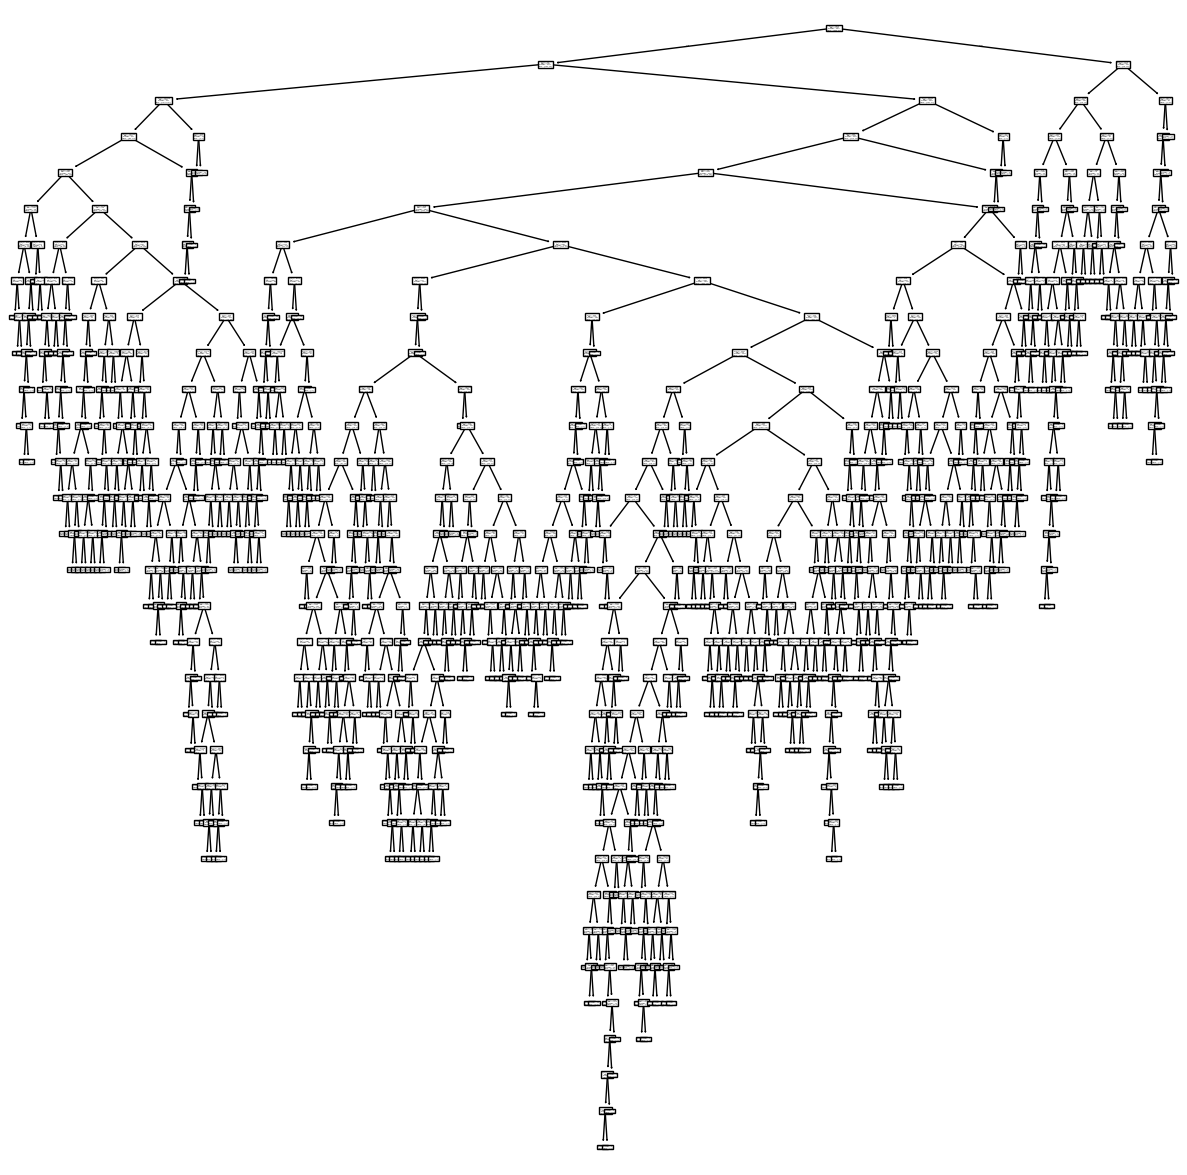

In [10]:
plt.figure(figsize=(15, 15))
tree.plot_tree(model)
plt.show()

In [11]:
# 2.Create model
model2 = tree.DecisionTreeClassifier(max_depth=8)

# 3. Train the model
model2.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=8)

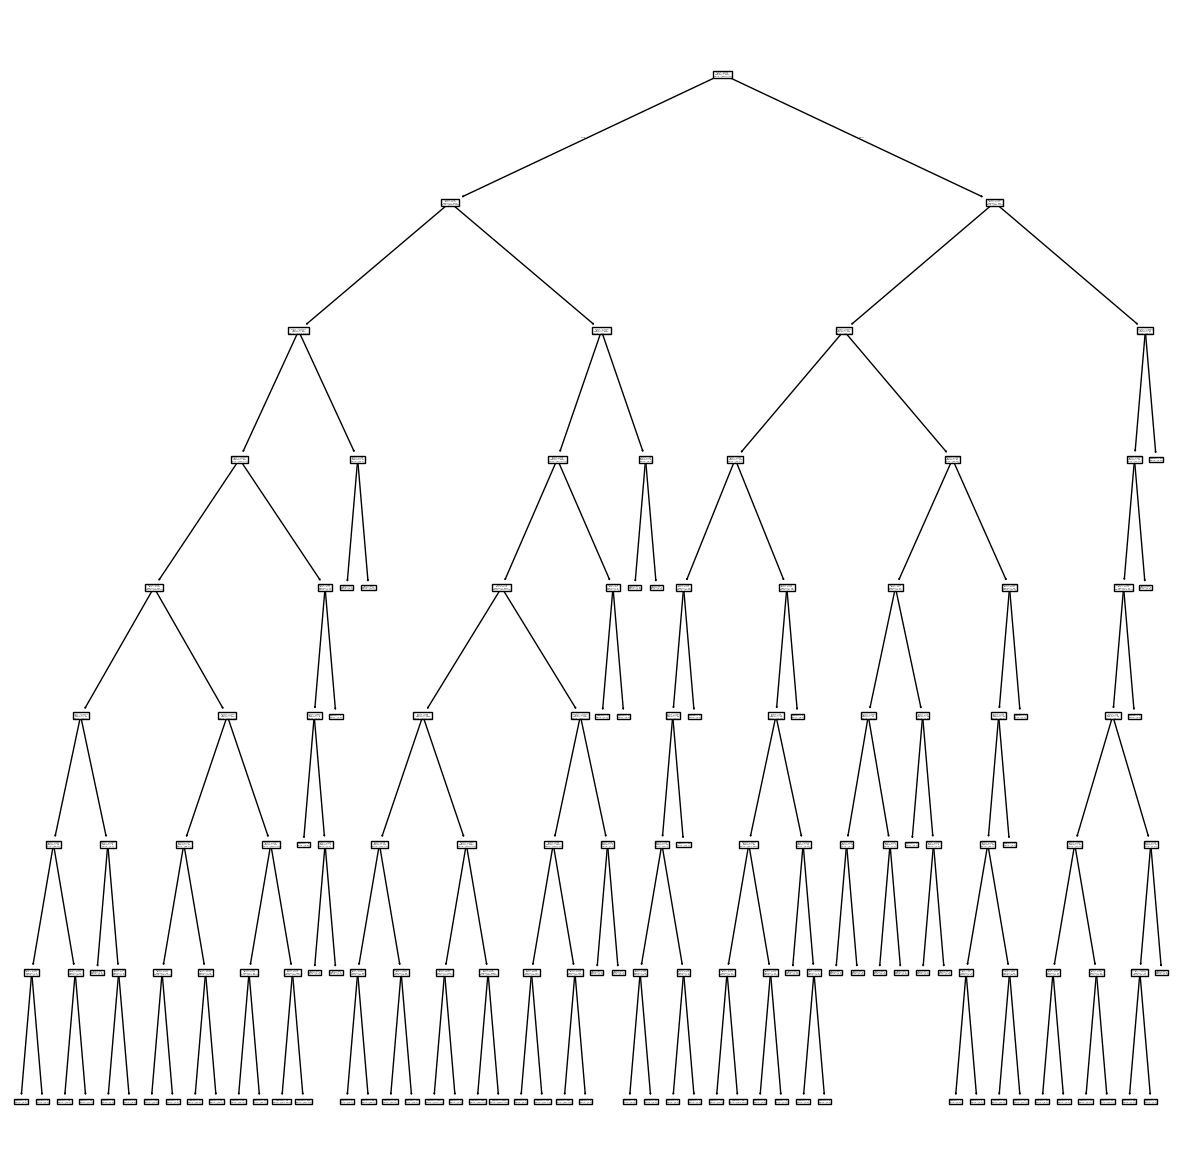

In [12]:
plt.figure(figsize=(15, 15))
tree.plot_tree(model2)
plt.show()

In [13]:
import graphviz

In [15]:
dot_data = tree.export_graphviz(model2, out_file=None,
                                feature_names=NUMERIC_COLUMNS,
                                class_names=["0", "1"],
                                filled=True)

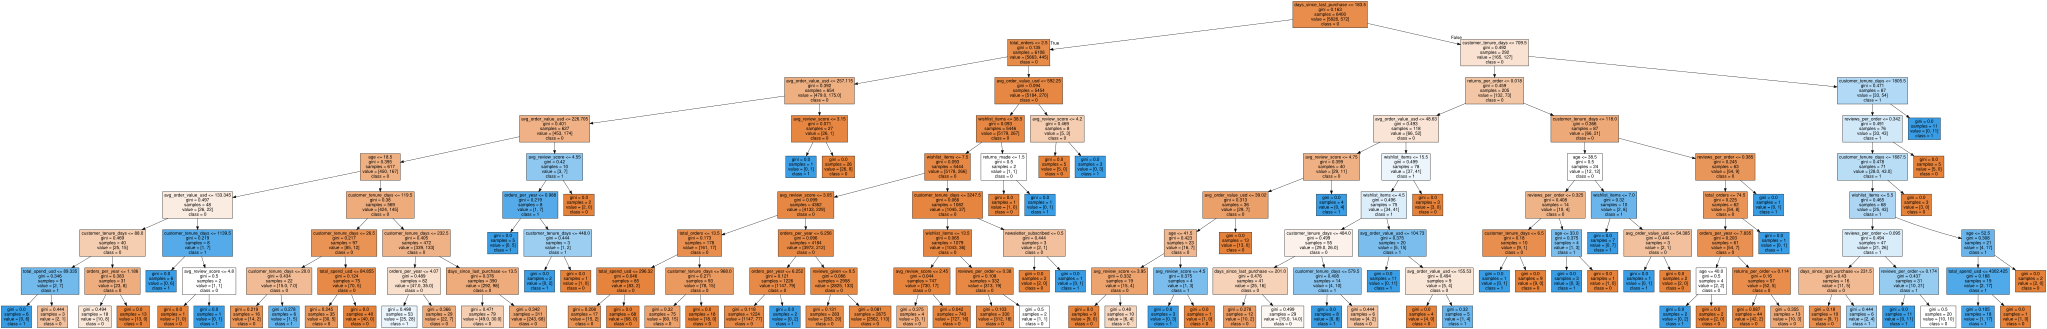

In [16]:
graph = graphviz.Source(dot_data, format="png")
graph

In [22]:
#4 prediction
y_pred = model2.predict(X_test)

In [21]:
acc = metrics.accuracy_score(y_test, y_pred)
prec = metrics.precision_score(y_test, y_pred, average="macro")
rec = metrics.recall_score(y_test, y_pred, average="macro")
f1 = metrics.f1_score(y_test, y_pred, average="macro")

In [23]:
print("Accuracy:", acc)
print("Precision:", prec)
print("Recall:", rec)
print("F1 Score:", f1)

Accuracy: 0.903125
Precision: 0.6593653562323897
Recall: 0.568408598950809
F1 Score: 0.5885859133807455


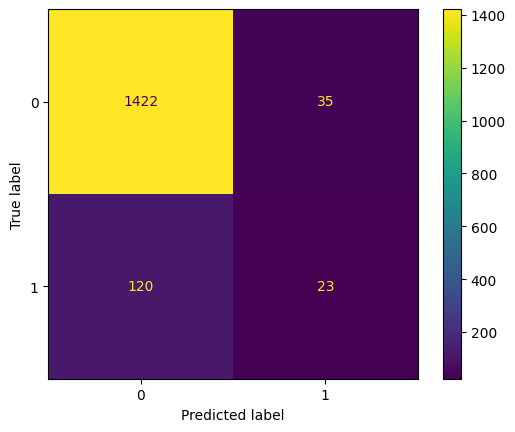

In [24]:
# Confusion Matrix
cm = metrics.confusion_matrix(y_test, y_pred)

disp= metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model2.classes_)
disp.plot()
plt.show()

## Random Forest

In [25]:
from sklearn import ensemble

In [27]:
#2. Create model
modelRF = ensemble.RandomForestClassifier(max_depth=8)

In [37]:
#3. Train the model
modelRF.fit(X_train, y_train)

RandomForestClassifier(max_depth=8)

In [38]:
# 4. Prediction
y_pred = modelRF.predict(X_test)

In [39]:
#5. Evaluation metrics
accRF = metrics.accuracy_score(y_test, y_pred)
precRF = metrics.precision_score(y_test, y_pred, average="macro")
recRF = metrics.recall_score(y_test, y_pred, average="macro")
f1RF = metrics.f1_score(y_test, y_pred, average="macro")

In [40]:
print("Accuracy:", accRF)
print("Precision:", precRF)
print("Recall:", recRF)
print("F1 Score:", f1RF)

Accuracy: 0.90875
Precision: 0.6226691808087157
Recall: 0.508430485094864
F1 Score: 0.49578671087166737


## Task
Buat Random Forest dengan max_depth = 2 angka terakhir NRP

Kerjakan di bawah ini

NRP : 2373022

Termasuk untuk evaluasi dan Confusion Matrix

In [41]:
#2. Create model
modelRF_NRP = ensemble.RandomForestClassifier(max_depth=22) #MAx Depthg 22 (2373022)

In [42]:
#3. Train the model
modelRF_NRP.fit(X_train, y_train)

RandomForestClassifier(max_depth=22)

In [46]:
# 4. Prediction
y_pred = modelRF_NRP.predict(X_test)

In [47]:
#5. Evaluation metrics
accRF_NRP = metrics.accuracy_score(y_test, y_pred)
precRF_NRP = metrics.precision_score(y_test, y_pred, average="macro")
recRF_NRP = metrics.recall_score(y_test, y_pred, average="macro")
f1RF_NRP = metrics.f1_score(y_test, y_pred, average="macro")

In [45]:
print("Accuracy:", accRF_NRP)
print("Precision:", precRF_NRP)
print("Recall:", recRF_NRP)
print("F1 Score:", f1RF_NRP)

Accuracy: 0.905625
Precision: 0.630510214055322
Recall: 0.5256346261836996
F1 Score: 0.5283451670021221


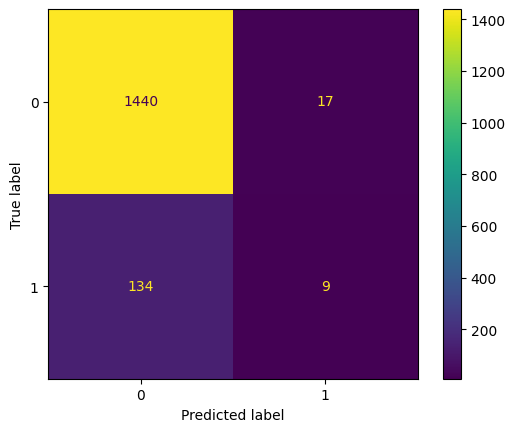

In [48]:
cmRF_NRP = metrics.confusion_matrix(y_test, y_pred)

disp= metrics.ConfusionMatrixDisplay(confusion_matrix=cmRF_NRP, display_labels=modelRF_NRP.classes_)
disp.plot()
plt.show()